# Method 4 · MRI–SPECT Fusion

Multimodal design: an MRI branch (grayscale, filtering, multi-class tumour segmentation) and a SPECT branch (uptake features) fused before a densely connected classifier. Image-level MRI–SPECT fusion is implemented and measured on 357 registered pairs. The MRI branch's dense network is trained on the shared MRI split and is what produces the four-class prediction; the paired set carries no diagnosis labels, so no classifier is trained on fused images.

**Modality:** MRI + SPECT
**Classifier:** DenseConvNetClassifier — DenseNet-BC style dense blocks (documented adaptation, not a novel architecture)
**Segmentation:** Multi-class 2D U-Net (4-way softmax over background + 3 tumour sub-regions)
**Optimisation:** —

Nothing here trains anything. Every number is read from a recorded evaluation,
every image is produced by the checkpoint on disk, and the training commands are
printed rather than run.

## 1 · Setup

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "backend").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np

from backend import config
from backend.methods.registry import get_method, load_engine, runtime_status
from backend.methods.common.metrics_store import read_metrics, metrics_for

plt.rcParams["figure.dpi"] = 110
print("project root :", ROOT)
print("device       :", config.DEVICE)
print("dataset      :", config.BRI_DATASET_PATH)

project root : /Users/syedasif/tumb
device       : mps
dataset      : /Users/syedasif/tumb/data/bri/archive


In [2]:
import json

def show(images, titles, width=4.2):
    """Draw images side by side with their titles."""
    images = [i for i in images if i is not None]
    fig, axes = plt.subplots(1, len(images), figsize=(width * len(images), width))
    for ax, image, title in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(image if image.ndim == 2 else image[..., ::-1], cmap="gray" if image.ndim == 2 else None)
        ax.set_title(title, fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def read(path):
    import cv2
    return None if path is None else cv2.imread(str(path), cv2.IMREAD_UNCHANGED)


def table(rows, headers):
    """A plain-text table, so the notebook reads the same with or without pandas."""
    widths = [max(len(str(r[i])) for r in [headers, *rows]) for i in range(len(headers))]
    line = "  ".join(h.ljust(w) for h, w in zip(headers, widths))
    print(line)
    print("  ".join("-" * w for w in widths))
    for row in rows:
        print("  ".join(str(c).ljust(w) for c, w in zip(row, widths)))

In [3]:
METHOD = "method2"
spec = get_method(METHOD)
status = runtime_status(spec)

print(f"Method {spec.display_number} — {spec.display_name}\n")
for stage in spec.pipeline:
    print(f"  {stage.id:<16}{stage.label:<28}{stage.description}")
print()
table([[role, w["architecture"], "yes" if w["present"] else "NO", w["model_version"] or "—"]
       for role, w in status["weights"].items()],
      ["role", "architecture", "checkpoint", "version"])

Method 4 — MRI–SPECT Multimodal Fusion-Based Brain Tumor Classification

  input           Input images                Single 2D image.
  gather          Data gathering              SPECT study set; BraTS used only for the segmentation head.
  grayscale       Grayscale conversion        Single-channel conversion before any filtering.
  filter          Filtering / denoising       Resize first, then median + bilateral edge-preserving filtering.
  segment         Multi-class segmentation    4-way softmax mask: background / necrotic core / edema / enhancing tumour.
  features        SPECT feature stage         Modality-specific descriptors: per-region uptake statistics and intensity histogram.
  fusion          MRI–SPECT fusion            Laplacian pyramid fusion of the MRI with the SPECT luminance, local-energy coefficient selection; SPECT chrominance carried through unchanged. Deterministic — nothing is trained.
  dcn             Dense Convolutional Network DenseNet-BC style densely conn

## 2 · The data

The images below come from the dataset's own **Testing** folder — the held-out
split the metrics further down were measured on. They are examples, not
predictions.

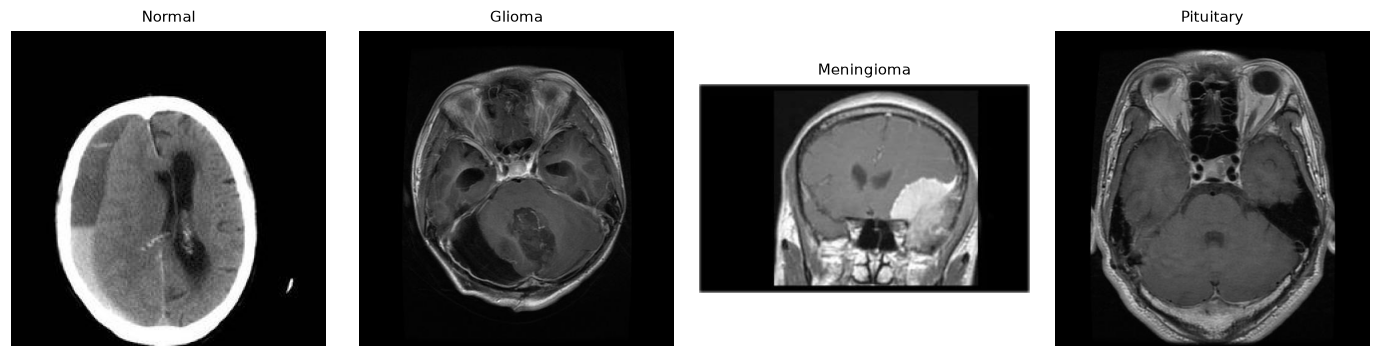

class       example file    
----------  ----------------
Normal      Te-noTr_0000.jpg
Glioma      Te-glTr_0000.jpg
Meningioma  Te-meTr_0000.jpg
Pituitary   Te-piTr_0000.jpg


In [4]:
root = config.BRI_DATASET_PATH / "Testing"
samples = {}
for class_key in spec.class_names:
    folder = root / ({"normal": "notumor"}.get(class_key, class_key))
    files = sorted(folder.glob("*.jpg"))[:1] if folder.is_dir() else []
    if files:
        samples[spec.class_labels[class_key]] = files[0]

show([read(p) for p in samples.values()], list(samples), width=3.2)
table([[label, path.name] for label, path in samples.items()], ["class", "example file"])

## 3 · Preprocessing

The geometry is read from the checkpoint, not chosen here: a model is served the
same transform it was trained with.

In [5]:
engine = load_engine(METHOD)
engine.load()
transform = status["weights"].get("classification", {}).get("transform_id")
print("transform recorded in the checkpoint:", transform or "—")

import importlib
transforms = importlib.import_module(spec.transforms_module)
spec_obj = transforms.get_spec(transform) if hasattr(transforms, "get_spec") else transforms.DEFAULT_SPEC
for k, v in spec_obj.to_dict().items():
    print(f"  {k:<16}{v}")

transform recorded in the checkpoint: m2-v1
  id              m2-v1
  image_size      128
  order           resize_then_filter
  median_ksize    3
  bilateral_d     5
  bilateral_sigma_color50.0
  bilateral_sigma_space50.0
  description     Grayscale → resize → median(3) → bilateral(5) → min-max scale.


## 4 · The model as loaded

Built from the checkpoint's own record of its hyper-parameters, then the stored
weights are loaded into it. A checkpoint that belonged to another method, or to
other classes, is refused rather than coerced.

In [6]:
model = getattr(engine, "model", None) or getattr(engine, "cls_model", None)
print(type(model).__name__)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")
print()
for key, value in (engine.meta if hasattr(engine, "meta") else engine.cls_meta).items():
    if key != "extra":
        print(f"  {key:<18}{value}")

DenseConvNetClassifier
521,808 parameters

  format            2
  method_id         method2
  architecture      DenseConvNetClassifier
  role              classification
  class_names       ['normal', 'glioma', 'meningioma', 'pituitary']
  image_size        128
  transform_id      m2-v1
  model_version     20261018-092436
  created_at        2026-10-18T09:24:36+00:00


## 5 · One prediction, with everything it produced

The class, the probabilities, and every image this method writes: the
preprocessed input it actually read, the segmentation mask, the Grad-CAM
heatmap, and — for the fusion method — the fused image.

In [7]:
image_path = list(samples.values())[0]
result = engine.predict(image_path.read_bytes())

print(f"input      : {image_path}")
print(f"prediction : {result.prediction}   {result.confidence}%")
print(f"model      : {result.model_version}   ({result.inference_time_s}s)\n")
for name, value in sorted(result.probabilities.items(), key=lambda kv: -kv[1]):
    print(f"  {name:<14}{'█' * int(value / 4):<25}{value:6.2f}%")

input      : /Users/syedasif/tumb/data/bri/archive/Testing/notumor/Te-noTr_0000.jpg
prediction : Normal   99.53%
model      : 20261018-092436   (0.5446s)

  Normal        ████████████████████████  99.53%
  Meningioma                               0.46%
  Glioma                                   0.01%
  Pituitary                                0.00%


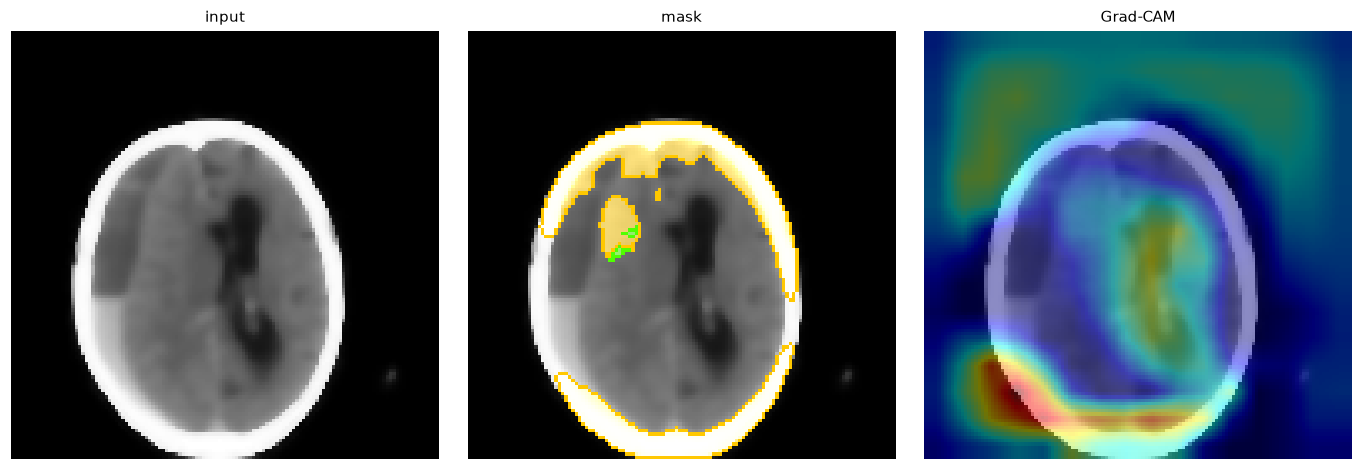

In [8]:
panels = [("input", result.original_path), ("mask", result.mask_path),
          ("Grad-CAM", result.overlay_path), ("fused", getattr(result, "fused_path", None))]
panels = [(label, path) for label, path in panels if path]
show([read(p) for _, p in panels], [label for label, _ in panels])

note = result.details.get("segmentation_note")
if note:
    print("mask:", note)
if result.details.get("gradcam_note"):
    print("Grad-CAM:", result.details["gradcam_note"])

## 6 · The recorded held-out evaluation

These numbers are not computed here. They were measured once, by the training
run, on the test split — and are read back from the metrics file so this
notebook cannot quietly disagree with the API.

In [9]:
metrics = metrics_for(METHOD)
table([[k, f"{metrics[k]:.4f}" if metrics[k] is not None else "—"]
       for k in ("accuracy", "precision", "recall", "specificity", "f1", "auc", "dice", "iou")],
      ["metric", "held-out test"])
print()
print(metrics["split"])

metric       held-out test
-----------  -------------
accuracy     0.9138       
precision    0.9124       
recall       0.9096       
specificity  0.9712       
f1           0.9103       
auc          0.9874       
dice         0.3725       
iou          0.2651       

dataset Training/Testing split; validation carved from Training only; image-level split; no patient identifiers, volume-grouped held-out test


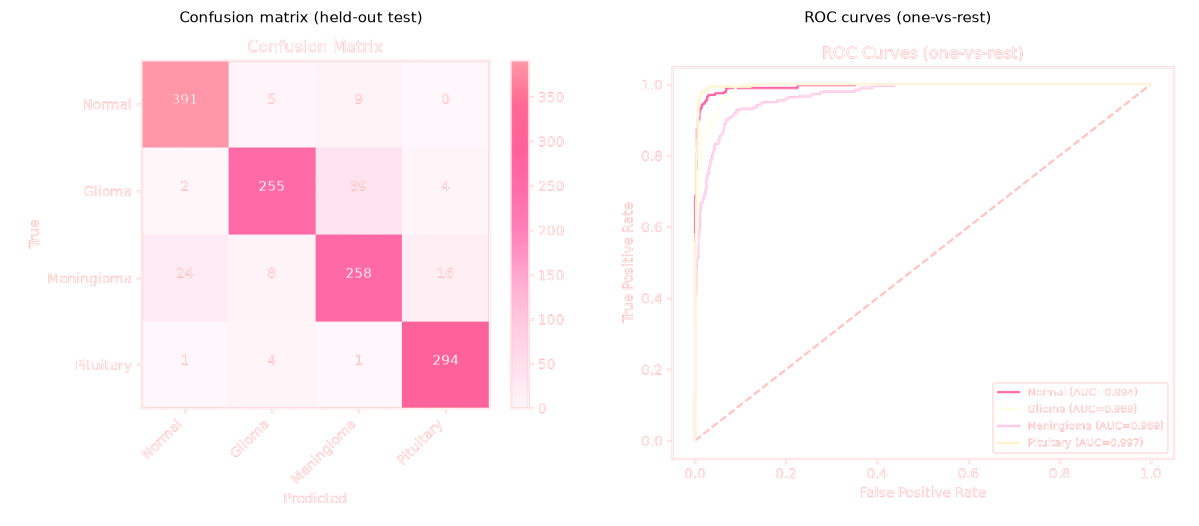

In [10]:
show([read(config.LOGS_DIR / "method2_cls_confusion_matrix.png"),
      read(config.LOGS_DIR / "method2_cls_roc.png")],
     ["Confusion matrix (held-out test)", "ROC curves (one-vs-rest)"], width=5.5)

## 7 · The fusion stage

This is the stage the method is named after, and it is deterministic — there is
nothing in it to train. The SPECT image goes to YCrCb, its colour channels pass
through untouched because the colour *is* the functional reading, and only the
luminance is fused with the MRI through a Laplacian pyramid.

Measured on all 357 registered pairs against the trivial averaging baseline.

In [11]:
fusion = read_metrics("method2")["fusion"]
print(f"{fusion['pairs']} pairs over {fusion['cases']} cases · {fusion['ms_per_pair']} ms/pair\n")
table([[k, f"{fusion['metrics'][k]['mean']:.4f}", f"{fusion['average_baseline'][k]['mean']:.4f}"]
       for k in ("qabf", "spatial_frequency", "entropy", "ssim_mri", "mutual_information_spect")],
      ["metric", "Laplacian fusion", "averaging baseline"])
print("\nQ_abf is the share of both sources' gradient information kept (0-1).")

357 pairs over 15 cases · 15.28 ms/pair

metric                    Laplacian fusion  averaging baseline
------------------------  ----------------  ------------------
qabf                      0.7079            0.3924            
spatial_frequency         0.0761            0.0414            
entropy                   4.2577            4.3867            
ssim_mri                  0.9204            0.8425            
mutual_information_spect  0.7751            1.1430            

Q_abf is the share of both sources' gradient information kept (0-1).


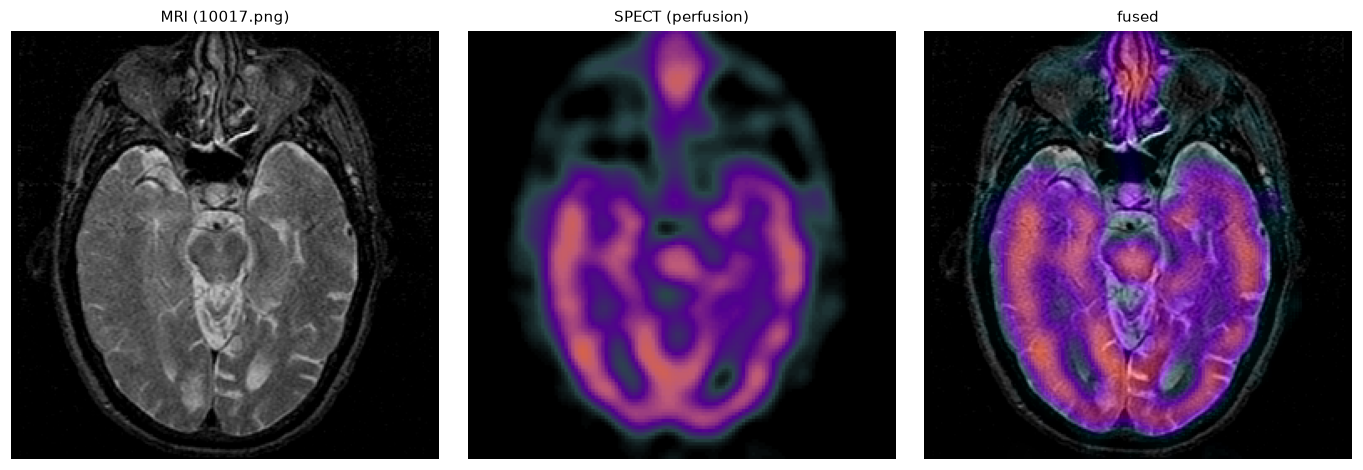

  entropy                   5.5083
  std                       0.1688
  spatial_frequency         0.0736
  mutual_information_mri    1.6563
  mutual_information_spect  0.8723
  ssim_mri                  0.9156
  ssim_spect                0.466
  qabf                      0.6643


In [12]:
from backend.methods.method2 import fusion as F

name = sorted(p.name for p in (config.PAIRED_MRI_SPECT_PATH / "MRI").glob("*.png"))[10]
mri = read(config.PAIRED_MRI_SPECT_PATH / "MRI" / name)
spect = read(config.PAIRED_MRI_SPECT_PATH / "SPECT" / name)
pair = F.fuse(mri, spect)
show([mri, spect, (pair.fused_rgb * 255).astype("uint8")],
     [f"MRI ({name})", "SPECT (perfusion)", "fused"])
for k, v in F.metrics(pair.mri, pair.spect_luminance, pair.fused_luminance).items():
    print(f"  {k:<26}{v}")

### Why no accuracy for the fusion

The paired set carries no diagnosis labels, so nothing can be trained or scored
for classification on it. The four-class prediction above comes from the trained
MRI branch, and this notebook never claims otherwise.

## 8 · Caveats

Every warning the method records travels with its numbers. They are part of the
result, not a footnote to it.

In [13]:
seen = set()
for section, values in read_metrics(METHOD).items():
    if not isinstance(values, dict):
        continue
    for warning in values.get("warnings", []) or []:
        if warning not in seen:
            seen.add(warning)
            print(f"[{section}] {warning}\n")

[classification] Trained on MRI only: this is the MRI branch of the MRI–SPECT fusion model. The image-level fusion stage is implemented and measured separately (`evaluate_fusion`), but the paired MRI–SPECT data carries no diagnosis labels, so no classifier is trained on fused images. These metrics describe MRI classification, not multimodal fusion.

[classification] The modality feature stage is active: region maps come from the trained multi-class segmentation head. That head's held-out foreground Dice is 0.3725, so the region descriptors below are approximate.

[classification] The Kaggle brain-MRI classification dataset carries no patient identifiers, so samples can only be grouped by image identity (training groups byte-identical copies together). Scores from this dataset may still be optimistic if the same patient appears under unrelated filenames.

[classification] Using the dataset's own Training/Testing split. It is an IMAGE-level split: this dataset ships no patient identifier

## 9 · Reproducing this

```bash
python -m backend.methods.method2.training.train_segmentation
python -m backend.methods.method2.training.train_classifier
python -m backend.methods.method2.training.evaluate_fusion
```

Or run every method on one image from a terminal:

```bash
python -m backend.cli.run_methods data/bri/archive/Testing/glioma/Te-gl_0012.jpg
```